PROJECT: /kaggle/working/ubiris_v2_project
Real preprocessed images: FOUND
Real image metadata: FOUND
Traditional augmentation metadata: FOUND
GAN preview: FOUND
Diffusion preview: FOUND


Evaluating real:   0%|          | 0/1000 [00:00<?, ?it/s]

Evaluating traditional_augmented:   0%|          | 0/1000 [00:00<?, ?it/s]

Evaluating gan_preview_grid:   0%|          | 0/1 [00:00<?, ?it/s]

Evaluating gan_epoch_preview_grid:   0%|          | 0/5 [00:00<?, ?it/s]

Evaluating diffusion_preview_grid:   0%|          | 0/1 [00:00<?, ?it/s]

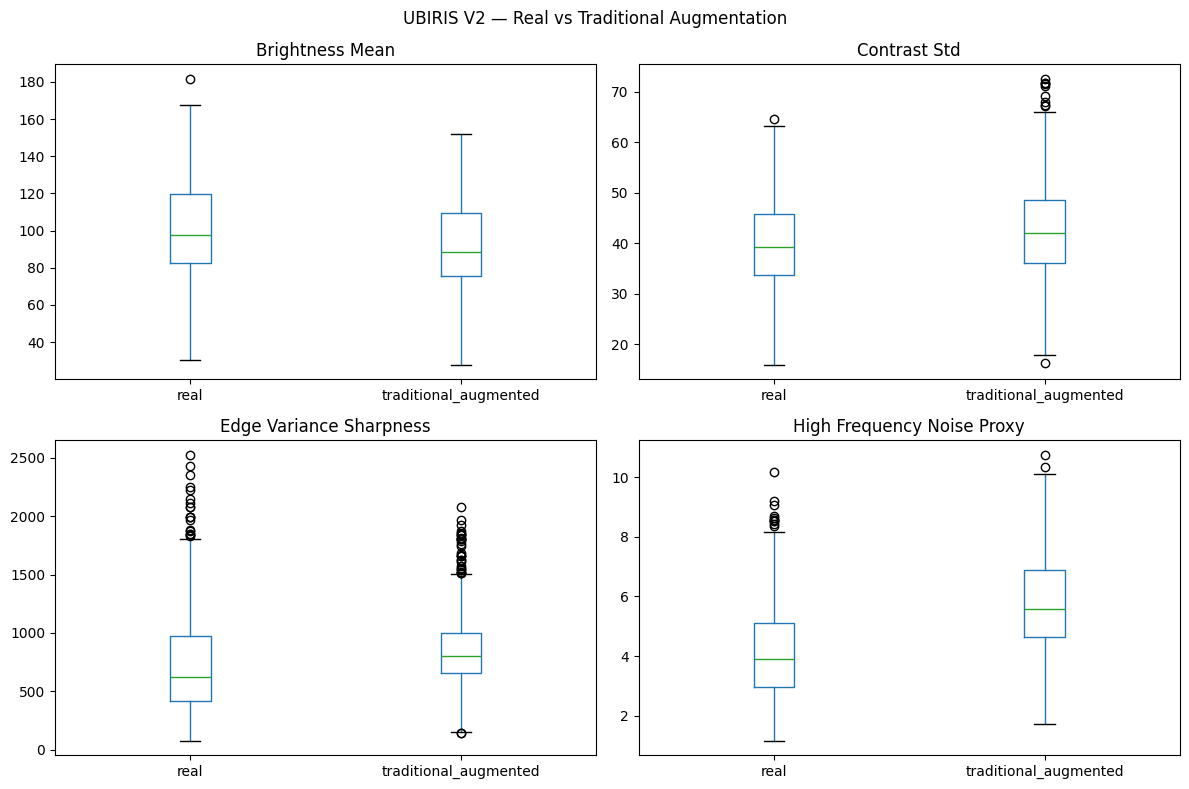


GROUP COUNTS
{
  "real": {
    "available_images": 5799,
    "evaluated_images": 1000,
    "sampling": "first 1000 sorted filenames"
  },
  "traditional_augmented": {
    "available_images": 8486,
    "evaluated_images": 1000,
    "sampling": "first 1000 sorted filenames"
  },
  "gan_preview_grid": {
    "available_images": 1,
    "evaluated_images": 1,
    "note": "Metrics describe the composite preview grid, not individual generated samples."
  },
  "gan_epoch_preview_grid": {
    "available_images": 5,
    "evaluated_images": 5,
    "note": "Each file is a grid containing multiple samples; not individual-image metrics."
  },
  "diffusion_preview_grid": {
    "available_images": 1,
    "evaluated_images": 1,
    "note": "Metrics describe the composite preview grid, not individual generated samples."
  }
}

SUMMARY
                 group  brightness_mean_count  brightness_mean_mean  brightness_mean_std  brightness_mean_min  brightness_mean_max  contrast_std_count  contrast_std_mean  

In [29]:

# ============================================================
# NOTEBOOK 08 — UBIRIS V2 IMAGE QUALITY & DIVERSITY EVALUATION
# Real vs Traditional Augmentation vs GAN vs Diffusion
# ============================================================

from pathlib import Path
from PIL import Image, ImageFilter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json, time, random
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

PROJECT = Path("/kaggle/working/ubiris_v2_project")
PRE_DIR = PROJECT / "notebook02_preprocessing"
QUALITY_DIR = PROJECT / "notebook03_quality_assessment"
TRAD_DIR = PROJECT / "notebook05_traditional_augmentation"
DIFF_DIR = PROJECT / "notebook06_diffusion_training"
GAN_DIR = PROJECT / "notebook07_gan_augmentation"

OUT_DIR = PROJECT / "notebook08_quality_diversity"
OUT_DIR.mkdir(parents=True, exist_ok=True)

REAL_DIR = PRE_DIR / "images_224"
REAL_META = PRE_DIR / "UBIRIS_V2_preprocessed_metadata.csv"
TRAD_META = TRAD_DIR / "UBIRIS_V2_traditional_augmented_metadata.csv"
GAN_PREVIEW = GAN_DIR / "UBIRIS_V2_GAN_training_samples_comparison.png"
DIFF_PREVIEW = DIFF_DIR / "UBIRIS_V2_ddpm_sample_preview.png"

print("PROJECT:", PROJECT)
for label, path in [
    ("Real preprocessed images", REAL_DIR),
    ("Real image metadata", REAL_META),
    ("Traditional augmentation metadata", TRAD_META),
    ("GAN preview", GAN_PREVIEW),
    ("Diffusion preview", DIFF_PREVIEW),
]:
    print(f"{label}: {'FOUND' if path.exists() else 'NOT FOUND'}")

assert REAL_DIR.is_dir(), f"Missing preprocessed images: {REAL_DIR}"

# ------------------------------------------------------------
# 1. Metric functions
# ------------------------------------------------------------
def calculate_metrics(image):
    """Compute simple grayscale image statistics, not biometric quality scores."""
    image = image.convert("L")
    arr = np.asarray(image, dtype=np.float32)

    brightness = float(arr.mean())
    contrast = float(arr.std())
    sharpness = float(np.asarray(image.filter(
        ImageFilter.FIND_EDGES
    ), dtype=np.float32).var())

    # Exploratory noise proxy: standard deviation of high-frequency residual.
    smooth = np.asarray(image.filter(
        ImageFilter.GaussianBlur(radius=1.0)
    ), dtype=np.float32)
    noise_proxy = float(np.std(arr - smooth))

    return {
        "brightness_mean": brightness,
        "contrast_std": contrast,
        "edge_variance_sharpness": sharpness,
        "high_frequency_noise_proxy": noise_proxy,
        "width": image.width,
        "height": image.height
    }

def evaluate_paths(paths, group, max_images=None):
    records = []
    errors = []

    paths = list(paths)
    if max_images is not None:
        paths = paths[:max_images]

    for path in tqdm(paths, desc=f"Evaluating {group}"):
        try:
            with Image.open(path) as im:
                metrics = calculate_metrics(im)
            records.append({
                "group": group,
                "filename": Path(path).name,
                "path": str(path),
                **metrics
            })
        except Exception as e:
            errors.append({
                "group": group,
                "path": str(path),
                "error": repr(e)
            })

    return records, errors

all_records = []
all_errors = []
group_counts = {}

# ------------------------------------------------------------
# 2. Real images: deterministic sample from the full dataset
# ------------------------------------------------------------
real_paths = sorted(REAL_DIR.glob("*.png"))
REAL_SAMPLE_LIMIT = 1000
real_sample = real_paths[:REAL_SAMPLE_LIMIT]

records, errors = evaluate_paths(real_sample, "real", max_images=None)
all_records.extend(records)
all_errors.extend(errors)
group_counts["real"] = {
    "available_images": len(real_paths),
    "evaluated_images": len(records),
    "sampling": f"first {len(real_sample)} sorted filenames"
}

# ------------------------------------------------------------
# 3. Traditional augmented images
# ------------------------------------------------------------
trad_image_dir = TRAD_DIR / "augmented_train_images"
if trad_image_dir.is_dir():
    trad_paths = sorted(trad_image_dir.glob("*.png"))
    # Match the evaluation workload to the real-image sample size.
    trad_sample = trad_paths[:min(len(trad_paths), REAL_SAMPLE_LIMIT)]
    records, errors = evaluate_paths(
        trad_sample, "traditional_augmented"
    )
    all_records.extend(records)
    all_errors.extend(errors)
    group_counts["traditional_augmented"] = {
        "available_images": len(trad_paths),
        "evaluated_images": len(records),
        "sampling": f"first {len(trad_sample)} sorted filenames"
    }
else:
    group_counts["traditional_augmented"] = {
        "available_images": 0,
        "evaluated_images": 0,
        "note": "Augmented image directory unavailable"
    }

# ------------------------------------------------------------
# 4. GAN previews: preview tiles are not a full generated dataset.
# ------------------------------------------------------------
if GAN_PREVIEW.is_file():
    records, errors = evaluate_paths([GAN_PREVIEW], "gan_preview_grid")
    all_records.extend(records)
    all_errors.extend(errors)
    group_counts["gan_preview_grid"] = {
        "available_images": 1,
        "evaluated_images": len(records),
        "note": "Metrics describe the composite preview grid, not individual generated samples."
    }
else:
    group_counts["gan_preview_grid"] = {
        "available_images": 0,
        "evaluated_images": 0,
        "note": "Composite GAN preview not found"
    }

# Evaluate individual epoch preview grids separately if present.
gan_epoch_paths = sorted((GAN_DIR / "samples").glob("UBIRIS_V2_GAN_epoch_*.png"))
if gan_epoch_paths:
    records, errors = evaluate_paths(gan_epoch_paths, "gan_epoch_preview_grid")
    all_records.extend(records)
    all_errors.extend(errors)
    group_counts["gan_epoch_preview_grid"] = {
        "available_images": len(gan_epoch_paths),
        "evaluated_images": len(records),
        "note": "Each file is a grid containing multiple samples; not individual-image metrics."
    }

# ------------------------------------------------------------
# 5. Diffusion preview grid: same caveat as GAN composite grid.
# ------------------------------------------------------------
if DIFF_PREVIEW.is_file():
    records, errors = evaluate_paths([DIFF_PREVIEW], "diffusion_preview_grid")
    all_records.extend(records)
    all_errors.extend(errors)
    group_counts["diffusion_preview_grid"] = {
        "available_images": 1,
        "evaluated_images": len(records),
        "note": "Metrics describe the composite preview grid, not individual generated samples."
    }
else:
    group_counts["diffusion_preview_grid"] = {
        "available_images": 0,
        "evaluated_images": 0,
        "note": "Diffusion preview not found"
    }

# ------------------------------------------------------------
# 6. Save detailed metrics and group summary
# ------------------------------------------------------------
metrics_df = pd.DataFrame(all_records)
errors_df = pd.DataFrame(
    all_errors, columns=["group", "path", "error"]
)

METRICS_CSV = OUT_DIR / "UBIRIS_V2_quality_diversity_metrics.csv"
SUMMARY_CSV = OUT_DIR / "UBIRIS_V2_quality_diversity_summary.csv"
ERRORS_CSV = OUT_DIR / "UBIRIS_V2_quality_diversity_errors.csv"
SUMMARY_JSON = OUT_DIR / "UBIRIS_V2_quality_diversity_summary.json"

metrics_df.to_csv(METRICS_CSV, index=False)
errors_df.to_csv(ERRORS_CSV, index=False)

metric_columns = [
    "brightness_mean",
    "contrast_std",
    "edge_variance_sharpness",
    "high_frequency_noise_proxy"
]

if not metrics_df.empty:
    summary_df = (
        metrics_df.groupby("group")[metric_columns]
        .agg(["count", "mean", "std", "min", "max"])
    )
    summary_df.columns = [
        f"{metric}_{stat}" for metric, stat in summary_df.columns
    ]
    summary_df = summary_df.reset_index()
else:
    summary_df = pd.DataFrame(columns=["group"])

summary_df.to_csv(SUMMARY_CSV, index=False)

summary = {
    "dataset": "UBIRIS V2",
    "notebook": "08_Image_Quality_and_Diversity_Evaluation",
    "real_images_available": len(real_paths),
    "real_images_evaluated": len(real_sample),
    "group_counts": group_counts,
    "metric_definitions": {
        "brightness_mean": "Mean grayscale pixel intensity",
        "contrast_std": "Standard deviation of grayscale pixel intensity",
        "edge_variance_sharpness": "Variance of a simple edge-filter response",
        "high_frequency_noise_proxy": "Standard deviation of image minus Gaussian-smoothed image; not a calibrated noise estimate"
    },
    "limitations": [
        "These statistics are simple exploratory image descriptors, not validated ocular biometric quality scores.",
        "Metrics computed on composite GAN/diffusion preview grids describe the grid, not each synthetic image.",
        "These statistics do not establish identity preservation, privacy, or improved recognition accuracy.",
        "The real and traditional groups use sorted filename samples, not a randomized or stratified sample."
    ],
    "errors": len(all_errors)
}
SUMMARY_JSON.write_text(json.dumps(summary, indent=2))

# ------------------------------------------------------------
# 7. Plot group means, only where comparable observations exist
# ------------------------------------------------------------
plot_groups = metrics_df[
    metrics_df["group"].isin(["real", "traditional_augmented"])
].copy()

if not plot_groups.empty:
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    for ax, metric in zip(axes.flat, metric_columns):
        plot_groups.boxplot(column=metric, by="group", ax=ax, grid=False)
        ax.set_title(metric.replace("_", " ").title())
        ax.set_xlabel("")
    fig.suptitle("UBIRIS V2 — Real vs Traditional Augmentation")
    fig.tight_layout()
    PLOT_PATH = OUT_DIR / "UBIRIS_V2_real_vs_traditional_quality.png"
    fig.savefig(PLOT_PATH, dpi=140, bbox_inches="tight")
    plt.show()
    plt.close(fig)
else:
    PLOT_PATH = None

print("\nGROUP COUNTS")
print(json.dumps(group_counts, indent=2))
print("\nSUMMARY")
print(summary_df.to_string(index=False) if not summary_df.empty else "No metrics available")
print("\nERRORS:", len(all_errors))
print("Metrics CSV:", METRICS_CSV)
print("Summary CSV:", SUMMARY_CSV)
print("Summary JSON:", SUMMARY_JSON)
print("Errors CSV:", ERRORS_CSV)
print("Comparison plot:", PLOT_PATH)


# Conclusion — Image Quality and Diversity Evaluation

This experiment evaluated simple image-level statistics for the UBIRIS V2 dataset and its traditional augmentation outputs. A deterministic sample of 1,000 real preprocessed images and 1,000 traditionally augmented images was analyzed. All evaluated files were processed successfully, with zero reported errors.

The evaluation measured mean grayscale brightness, pixel-intensity standard deviation as a contrast descriptor, edge-response variance as a sharpness proxy, and the standard deviation of the high-frequency residual after Gaussian smoothing as an exploratory noise proxy.

For the sampled real images, mean brightness was 100.54, mean contrast was 40.03, mean edge-variance sharpness was 735.50, and mean high-frequency noise proxy was 4.12. For the sampled traditionally augmented images, the corresponding values were 91.88, 42.88, 852.16, and 5.79.

These descriptive results indicate differences in intensity and local image structure between the sampled real and traditionally augmented images. They do not independently establish superior image quality, improved recognition performance, or increased dataset diversity.

GAN and diffusion outputs were available as composite preview grids. Their statistics were recorded separately, but they were not treated as individual-image measurements because the grid layout affects the calculated metrics. Consequently, a fair quantitative comparison of individual GAN-generated and diffusion-generated images was not established in this experiment.

**Limitations:** The real and traditional image samples were selected by sorted filename rather than randomized or stratified sampling. The metrics are simple exploratory descriptors, not validated ocular biometric quality measures. No formal perceptual-distance, distributional-diversity, identity-preservation, or downstream recognition evaluation was performed in this notebook.

**Conclusion:** The evaluation pipeline successfully measured basic image statistics and identified descriptive differences between real images and traditional augmentations. Further evaluation using individual generated images and suitable perceptual and biometric metrics would be required for stronger conclusions about synthetic-image quality and diversity.

In [30]:

from pathlib import Path
import zipfile
import pandas as pd
from IPython.display import display, FileLink

PROJECT = Path("/kaggle/working/ubiris_v2_project")
OUT_DIR = PROJECT / "notebook08_quality_diversity"
ZIP_PATH = Path("/kaggle/working/UBIRIS_V2_Notebook08_Results.zip")

required = [
    OUT_DIR / "UBIRIS_V2_quality_diversity_metrics.csv",
    OUT_DIR / "UBIRIS_V2_quality_diversity_summary.csv",
    OUT_DIR / "UBIRIS_V2_quality_diversity_summary.json",
    OUT_DIR / "UBIRIS_V2_quality_diversity_errors.csv",
    OUT_DIR / "UBIRIS_V2_real_vs_traditional_quality.png",
]

for path in required:
    assert path.is_file(), f"Missing artifact: {path}"

metrics = pd.read_csv(required[0])
summary = pd.read_csv(required[1])

print("METRICS:", metrics.shape)
print("SUMMARY:", summary.shape)
print("Evaluation errors:", len(pd.read_csv(required[3])))

for path in required:
    print(f"OK | {path.name} | {path.stat().st_size:,} bytes")

if ZIP_PATH.exists():
    ZIP_PATH.unlink()

count = 0
with zipfile.ZipFile(
    ZIP_PATH, "w",
    compression=zipfile.ZIP_DEFLATED,
    compresslevel=1,
    allowZip64=True
) as zf:
    for path in OUT_DIR.rglob("*"):
        if path.is_file():
            zf.write(path, path.relative_to(PROJECT))
            count += 1

print(f"\nFiles packaged: {count}")
print(f"ZIP size: {ZIP_PATH.stat().st_size / (1024**2):.2f} MB")
print("ZIP saved:", ZIP_PATH)

display(FileLink(
    str(ZIP_PATH),
    result_html_prefix="Download Notebook 08 results: "
))


METRICS: (2007, 9)
SUMMARY: (5, 21)
Evaluation errors: 0
OK | UBIRIS_V2_quality_diversity_metrics.csv | 423,661 bytes
OK | UBIRIS_V2_quality_diversity_summary.csv | 1,984 bytes
OK | UBIRIS_V2_quality_diversity_summary.json | 1,867 bytes
OK | UBIRIS_V2_quality_diversity_errors.csv | 17 bytes
OK | UBIRIS_V2_real_vs_traditional_quality.png | 84,051 bytes

Files packaged: 5
ZIP size: 0.15 MB
ZIP saved: /kaggle/working/UBIRIS_V2_Notebook08_Results.zip


/kaggle/working/UBIRIS_V2_Notebook08_Results.zip